Decaimento secular do SGP4: -29.0 m/dia
Densidade equivalente: 6.0286e-03 kg/km³ = 6.029e-12 kg/m³ (12.1x o valor antigo de 0.5e-3)
Iniciando Otimização do Estado Inicial (State Fitting)...
Ajuste Concluído!
Estado Original (SGP4):  [ 4.26822997e+03  5.28430856e+03 -4.00800000e-03 -3.70539500e+00
  2.98210500e+00  6.01226800e+00]
Estado Usado (RKF45):    [ 4.26821327e+03  5.28430613e+03 -3.00570000e-02 -3.70540300e+00
  2.98212900e+00  6.01229700e+00]
--------------------------------------------------
Calculando Método Runge-Kutta Adaptativo (120 Horas)...
Integração numérica concluída em 35868 passos (passo mediano = 12.0 s).
Calculando SGP4 (Biblioteca e Manual) usando a linha do tempo do RKF45...
GMST na época do TLE: 136.9927 graus
t =  24 h | |erro| = 0.371 km | R = -0.343  I = +0.049  C = -0.132 km
t =  72 h | |erro| = 1.164 km | R = -1.098  I = +0.085  C = -0.375 km
t = 120 h | |erro| = 1.949 km | R = -1.849  I = -0.007  C = -0.615 km


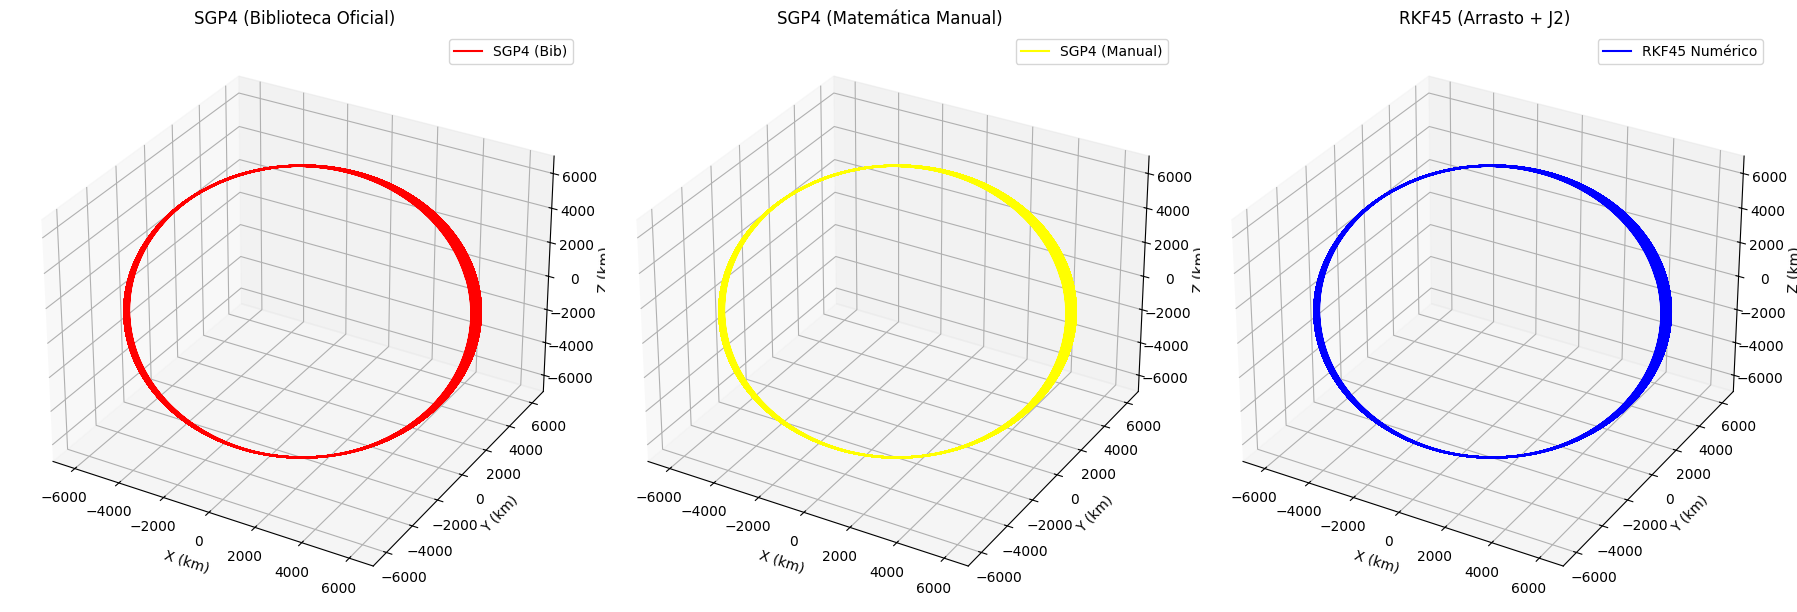

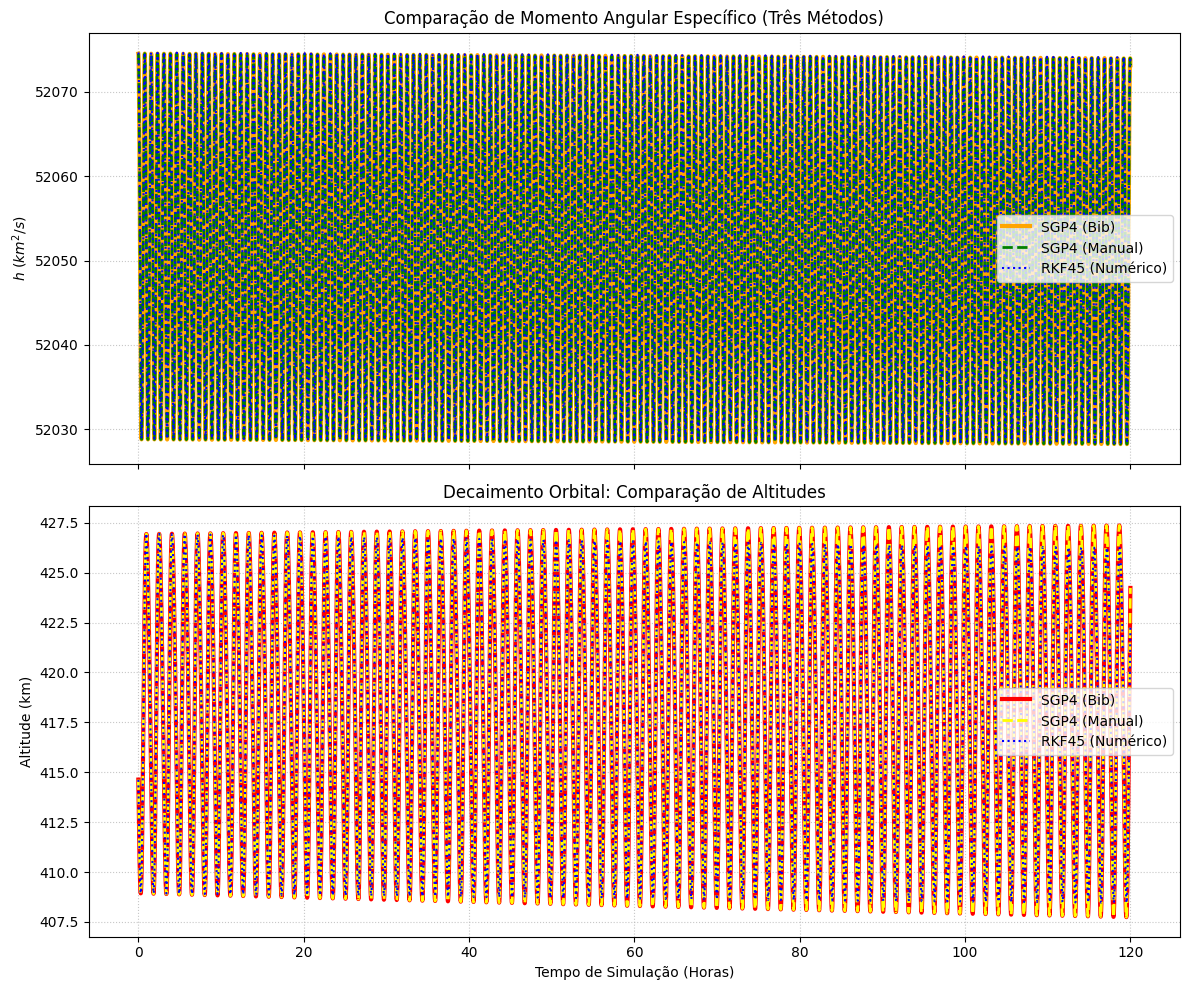

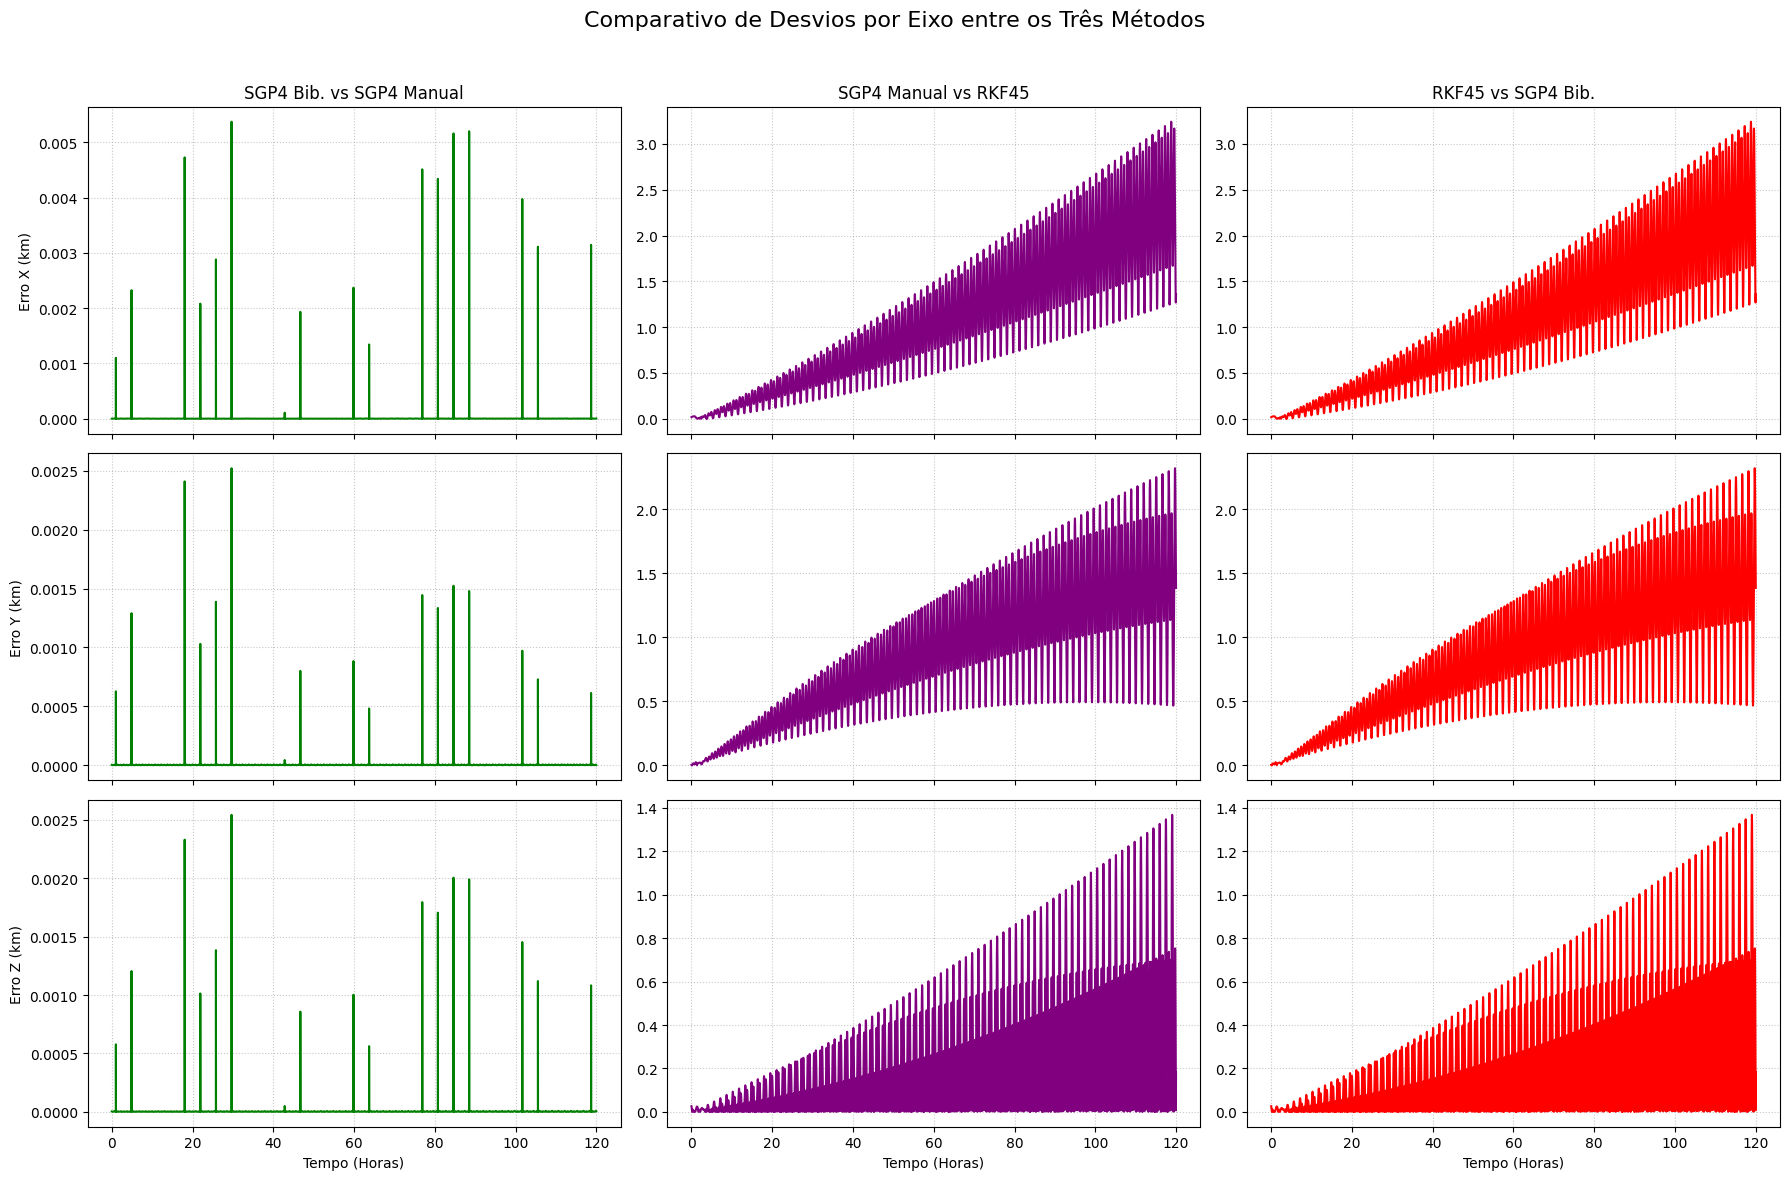

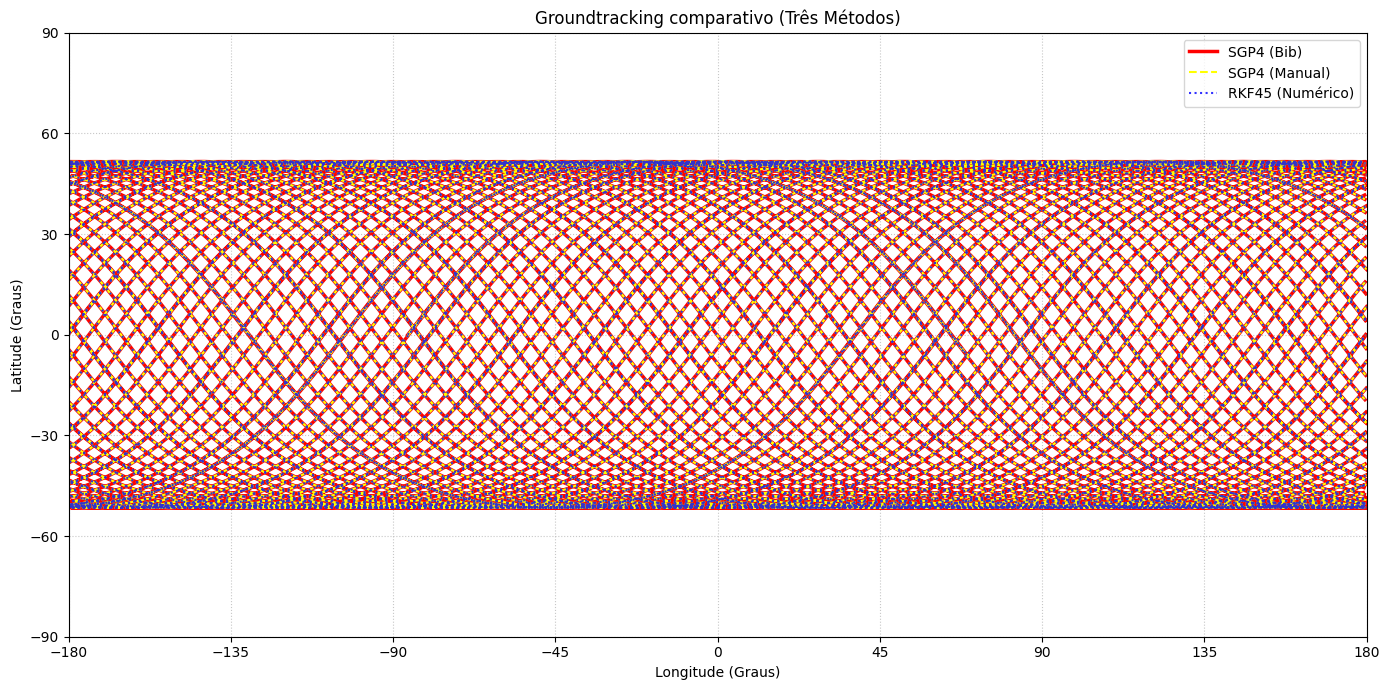

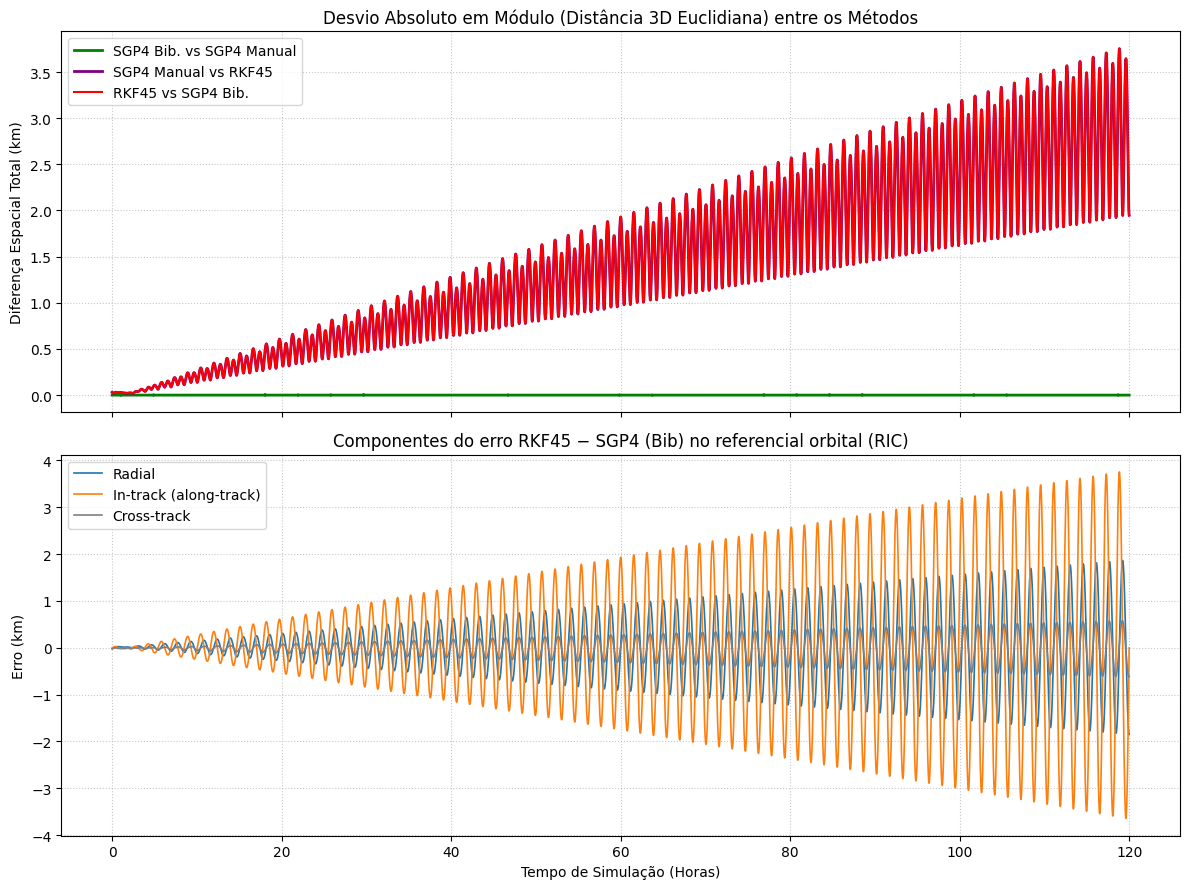

In [2]:
import math
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.optimize import least_squares
from scipy.interpolate import CubicHermiteSpline
from sgp4.api import Satrec, jday
from mpl_toolkits.mplot3d import Axes3D

# ====================================================================
# 1. DEFINIÇÃO DA CLASSE SGP4 (MANUAL)
# ====================================================================
class SGP4:
    def __init__(self):
        self.XMO = 0.0; self.XNODEO = 0.0; self.OMEGAO = 0.0; self.EO = 0.0
        self.XINCL = 0.0; self.XNO = 0.0; self.XNDT2O = 0.0; self.XNDD6O = 0.0
        self.BSTAR = 0.0; self.X = 0.0; self.Y = 0.0; self.Z = 0.0
        self.XDOT = 0.0; self.YDOT = 0.0; self.ZDOT = 0.0
        self.EPOCH = 0.0; self.DS50 = 0.0

        self.CK2 = 5.413080e-4
        self.CK4 = 0.62098875e-6
        self.E6A = 1e-6
        self.QOMS2T = 1.88027916e-9
        self.S = 1.01222928
        self.TOTHRD = 2.0 / 3.0
        self.XJ3 = -0.253881e-5
        self.XKE = 0.743669161e-1
        self.XKMPER = 6378.135
        self.AE = 1.0
        self.XMNPDA = 1440.0

        self.ISIMP = 0
        self.AODP = 0.0; self.XNODP = 0.0; self.C1 = 0.0; self.C4 = 0.0
        self.C5 = 0.0; self.D2 = 0.0; self.D3 = 0.0; self.D4 = 0.0
        self.T2COF = 0.0; self.T3COF = 0.0; self.T4COF = 0.0; self.T5COF = 0.0
        self.XMDOT = 0.0; self.OMGDOT = 0.0; self.XNODOT = 0.0
        self.OMGCOF = 0.0; self.XMCOF = 0.0; self.XNODCF = 0.0
        self.XLCOF = 0.0; self.AYCOF = 0.0; self.DELMO = 0.0
        self.ETA = 0.0; self.SINMO = 0.0

    @staticmethod
    def fmod2p(x):
        return x % (2.0 * math.pi)

    def load_tle(self, line1, line2):
        deg2rad = math.pi / 180.0
        self.XINCL = float(line2[8:16]) * deg2rad
        self.XNODEO = float(line2[17:25]) * deg2rad
        self.EO = float("0." + line2[26:33])
        self.OMEGAO = float(line2[34:42]) * deg2rad
        self.XMO = float(line2[43:51]) * deg2rad
        revs_per_day = float(line2[52:63])
        self.XNO = revs_per_day * (2.0 * math.pi) / 1440.0
        bstar_str = line1[53:61]
        bstar_sign = 1.0 if bstar_str[0] in [' ', '+'] else -1.0
        bstar_base = float(bstar_str[1:6]) * 1e-5
        bstar_exp = float(bstar_str[6:8])
        self.BSTAR = bstar_sign * bstar_base * (10 ** bstar_exp)

    def compute(self, iflag, tsince):
        if iflag != 0:
            A1 = (self.XKE / self.XNO) ** self.TOTHRD
            COSIO = math.cos(self.XINCL)
            THETA2 = COSIO * COSIO
            X3THM1 = 3.0 * THETA2 - 1.0
            EOSQ = self.EO * self.EO
            BETAO2 = 1.0 - EOSQ
            BETAO = math.sqrt(BETAO2)
            DEL1 = 1.5 * self.CK2 * X3THM1 / (A1 * A1 * BETAO * BETAO2)
            AO = A1 * (1.0 - DEL1 * (0.5 * self.TOTHRD + DEL1 * (1.0 + 134.0 / 81.0 * DEL1)))
            DELO = 1.5 * self.CK2 * X3THM1 / (AO * AO * BETAO * BETAO2)

            self.XNODP = self.XNO / (1.0 + DELO)
            self.AODP = AO / (1.0 - DELO)

            self.ISIMP = 0
            if (self.AODP * (1.0 - self.EO) / self.AE) < (220.0 / self.XKMPER + self.AE):
                self.ISIMP = 1

            S4 = self.S
            QOMS24 = self.QOMS2T
            PERIGE = (self.AODP * (1.0 - self.EO) - self.AE) * self.XKMPER

            if PERIGE < 156.0:
                if PERIGE > 98.0:
                    S4 = PERIGE - 78.0
                else:
                    S4 = 20.0
                QOMS24 = ((120.0 - S4) * self.AE / self.XKMPER) ** 4
                S4 = S4 / self.XKMPER + self.AE

            PINVSQ = 1.0 / (self.AODP * self.AODP * BETAO2 * BETAO2)
            TSI = 1.0 / (self.AODP - S4)
            self.ETA = self.AODP * self.EO * TSI
            ETASQ = self.ETA * self.ETA
            EETA = self.EO * self.ETA
            PSISQ = abs(1.0 - ETASQ)
            COEF = QOMS24 * (TSI ** 4)
            COEF1 = COEF / (PSISQ ** 3.5)

            C2 = COEF1 * self.XNODP * (self.AODP * (1.0 + 1.5 * ETASQ + EETA * (4.0 + ETASQ)) +
                 0.75 * self.CK2 * TSI / PSISQ * X3THM1 * (8.0 + 3.0 * ETASQ * (8.0 + ETASQ)))
            self.C1 = self.BSTAR * C2
            SINIO = math.sin(self.XINCL)
            A3OVK2 = -self.XJ3 / self.CK2 * (self.AE ** 3)
            C3 = COEF * TSI * A3OVK2 * self.XNODP * self.AE * SINIO / self.EO
            X1MTH2 = 1.0 - THETA2

            self.C4 = 2.0 * self.XNODP * COEF1 * self.AODP * BETAO2 * (self.ETA *
                  (2.0 + 0.5 * ETASQ) + self.EO * (0.5 + 2.0 * ETASQ) - 2.0 * self.CK2 * TSI /
                  (self.AODP * PSISQ) * (-3.0 * X3THM1 * (1.0 - 2.0 * EETA + ETASQ *
                  (1.5 - 0.5 * EETA)) + 0.75 * X1MTH2 * (2.0 * ETASQ - EETA *
                  (1.0 + ETASQ)) * math.cos(2.0 * self.OMEGAO)))

            self.C5 = 2.0 * COEF1 * self.AODP * BETAO2 * (1.0 + 2.75 * (ETASQ + EETA) + EETA * ETASQ)
            THETA4 = THETA2 * THETA2
            TEMP1 = 3.0 * self.CK2 * PINVSQ * self.XNODP
            TEMP2_VAL = TEMP1 * self.CK2 * PINVSQ
            TEMP3 = 1.25 * self.CK4 * PINVSQ * PINVSQ * self.XNODP

            self.XMDOT = self.XNODP + 0.5 * TEMP1 * BETAO * X3THM1 + 0.0625 * TEMP2_VAL * BETAO * \
                         (13.0 - 78.0 * THETA2 + 137.0 * THETA4)
            X1M5TH = 1.0 - 5.0 * THETA2
            self.OMGDOT = -0.5 * TEMP1 * X1M5TH + 0.0625 * TEMP2_VAL * (7.0 - 114.0 * THETA2 + \
                          395.0 * THETA4) + TEMP3 * (3.0 - 36.0 * THETA2 + 49.0 * THETA4)
            XHDOT1 = -TEMP1 * COSIO
            self.XNODOT = XHDOT1 + (0.5 * TEMP2_VAL * (4.0 - 19.0 * THETA2) + 2.0 * TEMP3 * \
                          (3.0 - 7.0 * THETA2)) * COSIO
            self.OMGCOF = self.BSTAR * C3 * math.cos(self.OMEGAO)
            self.XMCOF = -self.TOTHRD * COEF * self.BSTAR * self.AE / EETA
            self.XNODCF = 3.5 * BETAO2 * XHDOT1 * self.C1
            self.T2COF = 1.5 * self.C1
            self.XLCOF = 0.125 * A3OVK2 * SINIO * (3.0 + 5.0 * COSIO) / (1.0 + COSIO)
            self.AYCOF = 0.25 * A3OVK2 * SINIO
            self.DELMO = (1.0 + self.ETA * math.cos(self.XMO)) ** 3
            self.SINMO = math.sin(self.XMO)

            if self.ISIMP != 1:
                C1SQ = self.C1 * self.C1
                self.D2 = 4.0 * self.AODP * TSI * C1SQ
                TEMP = self.D2 * TSI * self.C1 / 3.0
                self.D3 = (17.0 * self.AODP + S4) * TEMP
                self.D4 = 0.5 * TEMP * self.AODP * TSI * (221.0 * self.AODP + 31.0 * S4) * self.C1
                self.T3COF = self.D2 + 2.0 * C1SQ
                self.T4COF = 0.25 * (3.0 * self.D3 + self.C1 * (12.0 * self.D2 + 10.0 * C1SQ))
                self.T5COF = 0.2 * (3.0 * self.D4 + 12.0 * self.C1 * self.D3 + 6.0 * self.D2 * self.D2 + \
                             15.0 * C1SQ * (2.0 * self.D2 + C1SQ))
            iflag = 0

        XMDF = self.XMO + self.XMDOT * tsince
        OMGADF = self.OMEGAO + self.OMGDOT * tsince
        XNODDF = self.XNODEO + self.XNODOT * tsince
        OMEGA = OMGADF
        XMP = XMDF
        TSQ = tsince * tsince
        XNODE = XNODDF + self.XNODCF * TSQ
        TEMPA = 1.0 - self.C1 * tsince
        TEMPE = self.BSTAR * self.C4 * tsince
        TEMPL = self.T2COF * TSQ

        if self.ISIMP != 1:
            DELOMG = self.OMGCOF * tsince
            DELM = self.XMCOF * ((1.0 + self.ETA * math.cos(XMDF)) ** 3 - self.DELMO)
            TEMP = DELOMG + DELM
            XMP = XMDF + TEMP
            OMEGA = OMGADF - TEMP
            TCUBE = TSQ * tsince
            TFOUR = tsince * TCUBE
            TEMPA = TEMPA - self.D2 * TSQ - self.D3 * TCUBE - self.D4 * TFOUR
            TEMPE = TEMPE + self.BSTAR * self.C5 * (math.sin(XMP) - self.SINMO)
            TEMPL = TEMPL + self.T3COF * TCUBE + TFOUR * (self.T4COF + tsince * self.T5COF)

        A = self.AODP * (TEMPA ** 2)
        E = self.EO - TEMPE
        XL = XMP + OMEGA + XNODE + self.XNODP * TEMPL
        BETA = math.sqrt(1.0 - E * E)
        XN = self.XKE / (A ** 1.5)

        AXN = E * math.cos(OMEGA)
        TEMP = 1.0 / (A * BETA * BETA)
        XLL = TEMP * self.XLCOF * AXN
        AYNL = TEMP * self.AYCOF
        XLT = XL + XLL
        AYN = E * math.sin(OMEGA) + AYNL

        CAPU = self.fmod2p(XLT - XNODE)
        TEMP2_KEP = CAPU

        for _ in range(10):
            SINEPW = math.sin(TEMP2_KEP)
            COSEPW = math.cos(TEMP2_KEP)
            TEMP3_K = AXN * SINEPW
            TEMP4_K = AYN * COSEPW
            TEMP5_K = AXN * COSEPW
            TEMP6_K = AYN * SINEPW
            EPW = (CAPU - TEMP4_K + TEMP3_K - TEMP2_KEP) / (1.0 - TEMP5_K - TEMP6_K) + TEMP2_KEP
            if abs(EPW - TEMP2_KEP) <= self.E6A:
                break
            TEMP2_KEP = EPW

        ECOSE = TEMP5_K + TEMP6_K
        ESINE = TEMP3_K - TEMP4_K
        ELSQ = AXN * AXN + AYN * AYN
        TEMP_PL = 1.0 - ELSQ
        PL = A * TEMP_PL
        R = A * (1.0 - ECOSE)
        TEMP1_R = 1.0 / R
        RDOT = self.XKE * math.sqrt(A) * ESINE * TEMP1_R
        RFDOT = self.XKE * math.sqrt(PL) * TEMP1_R
        TEMP2_R = A * TEMP1_R
        BETAL = math.sqrt(TEMP_PL)
        TEMP3_R = 1.0 / (1.0 + BETAL)

        COSU = TEMP2_R * (COSEPW - AXN + AYN * ESINE * TEMP3_R)
        SINU = TEMP2_R * (SINEPW - AYN - AXN * ESINE * TEMP3_R)

        U = math.atan2(SINU, COSU)
        SIN2U = 2.0 * SINU * COSU
        COS2U = 2.0 * COSU * COSU - 1.0
        TEMP_UP = 1.0 / PL
        TEMP1_UP = self.CK2 * TEMP_UP
        TEMP2_UP = TEMP1_UP * TEMP_UP

        COSIO = math.cos(self.XINCL)
        SINIO = math.sin(self.XINCL)
        THETA2 = COSIO * COSIO
        X3THM1 = 3.0 * THETA2 - 1.0
        X1MTH2 = 1.0 - THETA2
        X7THM1 = 7.0 * THETA2 - 1.0

        RK = R * (1.0 - 1.5 * TEMP2_UP * BETAL * X3THM1) + 0.5 * TEMP1_UP * X1MTH2 * COS2U
        UK = U - 0.25 * TEMP2_UP * X7THM1 * SIN2U
        XNODEK = XNODE + 1.5 * TEMP2_UP * COSIO * SIN2U
        XINCK = self.XINCL + 1.5 * TEMP2_UP * COSIO * SINIO * COS2U
        RDOTK = RDOT - XN * TEMP1_UP * X1MTH2 * SIN2U
        RFDOTK = RFDOT + XN * TEMP1_UP * (X1MTH2 * COS2U + 1.5 * X3THM1)

        SINUK = math.sin(UK)
        COSUK = math.cos(UK)
        SINIK = math.sin(XINCK)
        COSIK = math.cos(XINCK)
        SINNOK = math.sin(XNODEK)
        COSNOK = math.cos(XNODEK)

        XMX = -SINNOK * COSIK
        XMY = COSNOK * COSIK
        UX = XMX * SINUK + COSNOK * COSUK
        UY = XMY * SINUK + SINNOK * COSUK
        UZ = SINIK * SINUK
        VX = XMX * COSUK - COSNOK * SINUK
        VY = XMY * COSUK - SINNOK * SINUK
        VZ = SINIK * COSUK

        self.XDOT = (RDOTK * UX + RFDOTK * VX) * self.XKMPER / 60.0
        self.YDOT = (RDOTK * UY + RFDOTK * VY) * self.XKMPER / 60.0
        self.ZDOT = (RDOTK * UZ + RFDOTK * VZ) * self.XKMPER / 60.0

        self.X = RK * UX * self.XKMPER
        self.Y = RK * UY * self.XKMPER
        self.Z = RK * UZ * self.XKMPER

        return (self.X, self.Y, self.Z, self.XDOT, self.YDOT, self.ZDOT)


# ====================================================================
# 2. DEFINIÇÃO DAS FUNÇÕES DO RUNGE-KUTTA E FÍSICA
# ====================================================================
MU = 398601.87717000005
CD = 1.45
AREA = 378
MASSA = 475861.00
J2 = 0.00108263
R_EARTH = 6378.137
W_EARTH = 7.292115e-5     # Rotação da Terra (rad/s)


RHO_KG_KM3 = None

def acceleration_3d_dragJ2(x, t):
    r_vec = x[:3]
    v_vec = x[3:]
    r_norm = np.linalg.norm(r_vec)

    if r_norm == 0: raise ValueError("Colisão!")

    x_pos, y_pos, z_pos = r_vec
    r2 = r_norm**2
    z2 = z_pos**2

    # Aceleração Gravitacional Central
    a_grav = -MU * r_vec / (r_norm**3)

    # Harmônico J2
    f_j2 = (3/2) * J2 * (MU * R_EARTH**2) / (r_norm**5)
    ax_j2 = f_j2 * x_pos * (5 * (z2/r2) - 1)
    ay_j2 = f_j2 * y_pos * (5 * (z2/r2) - 1)
    az_j2 = f_j2 * z_pos * (5 * (z2/r2) - 3)

    a_j = np.array([ax_j2, ay_j2, az_j2])

    rho_kg_km3 = RHO_KG_KM3

    # Vento Relativo (Co-rotação da Atmosfera): v_rel = v - ω × r
    v_rel = np.array([
        v_vec[0] + W_EARTH * y_pos,
        v_vec[1] - W_EARTH * x_pos,
        v_vec[2]
    ])
    v_rel_norm = np.linalg.norm(v_rel)

    # Arrasto Atmosférico: a = -1/2 · (Cd·A/m) · ρ · |v_rel| · v_rel   [km/s²]
    area_km2 = AREA / 1e6
    drag_mag = 0.5 * (CD * area_km2 / MASSA) * rho_kg_km3 * v_rel_norm
    a_drag = -drag_mag * v_rel

    return np.concatenate((v_vec, a_grav + a_j + a_drag))

def runge_kutta_fehlberg(g, x, t, h):
    x = x.astype(float)
    k1 = h * g(x, t)
    k2 = h * g(x + k1 / 4.0, t + h / 4.0)
    k3 = h * g(x + 3.0 * k1 / 32.0 + 9.0 * k2 / 32.0, t + 3.0 * h / 8.0)
    k4 = h * g(x + 1932.0 * k1 / 2197.0 - 7200.0 * k2 / 2197.0 + 7296.0 * k3 / 2197.0, t + 12.0 * h / 13.0)
    k5 = h * g(x + 439.0 * k1 / 216.0 - 8.0 * k2 + 3680.0 * k3 / 513.0 - 845.0 * k4 / 4104.0, t + h)
    k6 = h * g(x - 8.0 * k1 / 27.0 + 2 * k2 - 3544.0 * k3 / 2565 + 1859.0 * k4 / 4104.0 - 11.0 * k5 / 40.0, t + h / 2.0)

    w = x + 25.0 * k1 / 216.0 + 1408.0 * k3 / 2565.0 + 2197.0 * k4 / 4104.0 - k5 / 5.0
    q = x + 16.0 * k1 / 135.0 + 6656.0 * k3 / 12825.0 + 28561.0 * k4 / 56430.0 - 9.0 * k5 / 50.0 + 2.0 * k6 / 55.0
    return w, q

def rk_adaptive(ode, rhs, y0, t0=0.0, TOL=1e-12, tmax=1.0, h_max=30.0, h0=10.0):
    y, t = [np.array(y0, dtype=float)], [t0]
    h = h0
    i = 0
    while t[-1] < tmax:
        h = min(h, h_max, tmax - t[-1])          # não ultrapassa h_max nem o tempo final

        w, q = ode(rhs, y[-1], t[-1], h)
        err = np.linalg.norm(w - q) / max(np.linalg.norm(y[-1]), 1e-8)

        fator = 0.9 * (TOL / max(err, 1e-30))**0.2
        fator = min(max(fator, 0.2), 5.0)

        if err > TOL:                             # passo rejeitado: reduz e tenta de novo
            h *= fator
            continue

        y.append(q)                               # aceita a solução de 5ª ordem
        t.append(t[-1] + h)
        i += 1
        h *= fator                                # ajusta o próximo passo

    return np.array(y), np.array(t), i


# ====================================================================
# 3. PREPARAÇÃO DO ESTADO INICIAL E DA DENSIDADE
# ====================================================================
s_line1 = "1 25544U 98067A   26218.50541180  .00004487  00000+0  88448-4 0  9991"
s_line2 = "2 25544  51.6323  51.0716 0007292  18.8673 341.2584 15.49364501579551"

sat_sgp4 = Satrec.twoline2rv(s_line1, s_line2)

iss = SGP4()
iss.load_tle(s_line1, s_line2)
iss.compute(iflag=1, tsince=0)
x0, y0, z0, vx0, vy0, vz0 = iss.compute(iflag=0, tsince=0)

u0_chute = np.array([x0, y0, z0, vx0, vy0, vz0])
T_MAX_SEGUNDOS = 432000 # 120 horas / 5 dias

adot_sgp4 = -2.0 * iss.AODP * iss.C1 * iss.XKMPER / 60.0            # km/s
B_bal = CD * (AREA / 1e6) / MASSA                                    # km²/kg
r0v, v0v = u0_chute[:3], u0_chute[3:]
v0_rel = v0v - np.cross([0.0, 0.0, W_EARTH], r0v)
a0 = 1.0 / (2.0 / np.linalg.norm(r0v) - v0v @ v0v / MU)               # semieixo (vis-viva)
RHO_KG_KM3 = -adot_sgp4 / (B_bal * (a0**2 / MU) * np.linalg.norm(v0_rel) * (v0v @ v0_rel))
print(f"Decaimento secular do SGP4: {adot_sgp4*86400*1e3:.1f} m/dia")
print(f"Densidade equivalente: {RHO_KG_KM3:.4e} kg/km³ = {RHO_KG_KM3*1e-9:.3e} kg/m³ "
      f"({RHO_KG_KM3/0.5e-3:.1f}x o valor antigo de 0.5e-3)")

USAR_AJUSTE = True

if USAR_AJUSTE:
    print("Iniciando Otimização do Estado Inicial (State Fitting)...")
    tempos_fit = np.linspace(0, 10800, 50)        # 3 h (~2 órbitas) de pontos do SGP4
    pos_sgp4_fit = np.array([sat_sgp4.sgp4_tsince(t / 60.0)[1] for t in tempos_fit])

    def cost_function(state_guess):
        y_fit, t_fit, _ = rk_adaptive(runge_kutta_fehlberg, acceleration_3d_dragJ2,
                                      y0=state_guess, t0=0.0, TOL=1e-12, tmax=10800, h_max=30.0)
        spline = CubicHermiteSpline(t_fit, y_fit[:, :3], y_fit[:, 3:])
        return (spline(tempos_fit) - pos_sgp4_fit).ravel()

    resultado_fit = least_squares(cost_function, u0_chute, method='lm',
                                  x_scale=np.array([1, 1, 1, 1e-3, 1e-3, 1e-3]))
    u0_refinado = resultado_fit.x
    print("Ajuste Concluído!")
else:
    u0_refinado = u0_chute.copy()

print(f"Estado Original (SGP4):  {np.round(u0_chute, 6)}")
print(f"Estado Usado (RKF45):    {np.round(u0_refinado, 6)}")
print("-" * 50)


# ====================================================================
# 4. INTEGRAÇÃO FINAL E GERAÇÃO DOS DADOS
# ====================================================================
print("Calculando Método Runge-Kutta Adaptativo (120 Horas)...")
pos_dragJ2, times, iterations_dragJ2 = rk_adaptive(
    runge_kutta_fehlberg,
    acceleration_3d_dragJ2,
    y0=u0_refinado,
    t0=0.0,
    TOL=1e-12,      
    tmax=T_MAX_SEGUNDOS,
    h_max=30.0     
)
print(f"Integração numérica concluída em {iterations_dragJ2} passos "
      f"(passo mediano = {np.median(np.diff(times)):.1f} s).")

posicoes_lib, velocidades_lib = [], []
posicoes_man, velocidades_man = [], []

print("Calculando SGP4 (Biblioteca e Manual) usando a linha do tempo do RKF45...")
for t_seg in times:
    t_min = t_seg / 60.0

    e, r, v = sat_sgp4.sgp4_tsince(t_min)
    posicoes_lib.append(r)
    velocidades_lib.append(v)

    x, y, z, vx, vy, vz = iss.compute(iflag=0, tsince=t_min)
    posicoes_man.append([x, y, z])
    velocidades_man.append([vx, vy, vz])

pos_lib_arr = np.array(posicoes_lib)
vel_lib_arr = np.array(velocidades_lib)

pos_man_arr = np.array(posicoes_man)
vel_man_arr = np.array(velocidades_man)

pos_rkf_arr = pos_dragJ2[:, :3]
vel_rkf_arr = pos_dragJ2[:, 3:]
tempos_horas = times / 3600.0


# ====================================================================
# 5. PLOTAGEM DOS GRÁFICOS COMPARATIVOS
# ====================================================================

# --- A) Gráficos 3D Lado a Lado (Orbitas Separadas) ---
fig_3d = plt.figure(figsize=(18, 6))

ax1 = fig_3d.add_subplot(131, projection='3d')
ax1.plot(pos_lib_arr[:,0], pos_lib_arr[:,1], pos_lib_arr[:,2], color='red', linewidth=1.5, label='SGP4 (Bib)')
ax1.set_title('SGP4 (Biblioteca Oficial)')
ax1.set_xlabel('X (km)')
ax1.set_ylabel('Y (km)')
ax1.set_zlabel('Z (km)')
ax1.set_xlim([-7000, 7000]); ax1.set_ylim([-7000, 7000]); ax1.set_zlim([-7000, 7000])
ax1.legend()

ax2 = fig_3d.add_subplot(132, projection='3d')
ax2.plot(pos_man_arr[:,0], pos_man_arr[:,1], pos_man_arr[:,2], color='yellow', linewidth=1.5, label='SGP4 (Manual)')
ax2.set_title('SGP4 (Matemática Manual)')
ax2.set_xlabel('X (km)')
ax2.set_ylabel('Y (km)')
ax2.set_zlabel('Z (km)')
ax2.set_xlim([-7000, 7000]); ax2.set_ylim([-7000, 7000]); ax2.set_zlim([-7000, 7000])
ax2.legend()

ax3 = fig_3d.add_subplot(133, projection='3d')
ax3.plot(pos_rkf_arr[:,0], pos_rkf_arr[:,1], pos_rkf_arr[:,2], color='blue', linewidth=1.5, label='RKF45 Numérico')
ax3.set_title('RKF45 (Arrasto + J2)')
ax3.set_xlabel('X (km)')
ax3.set_ylabel('Y (km)')
ax3.set_zlabel('Z (km)')
ax3.set_xlim([-7000, 7000]); ax3.set_ylim([-7000, 7000]); ax3.set_zlim([-7000, 7000])
ax3.legend()

plt.tight_layout()


# --- B) Grandezas Analíticas: Altitude e Momento Angular (Triplo Comparativo) ---
fig_metrics, (ax_h, ax_alt) = plt.subplots(2, 1, figsize=(12, 10), sharex=True)

h_lib = np.linalg.norm(np.cross(pos_lib_arr, vel_lib_arr), axis=1)
h_man = np.linalg.norm(np.cross(pos_man_arr, vel_man_arr), axis=1)
h_rkf = np.linalg.norm(np.cross(pos_rkf_arr, vel_rkf_arr), axis=1)

ax_h.plot(tempos_horas, h_lib, color='orange', linewidth=3, label='SGP4 (Bib)')
ax_h.plot(tempos_horas, h_man, color='green', linewidth=2, linestyle='--', label='SGP4 (Manual)')
ax_h.plot(tempos_horas, h_rkf, color='blue', linewidth=1.5, linestyle=':', label='RKF45 (Numérico)')
ax_h.set_title('Comparação de Momento Angular Específico (Três Métodos)')
ax_h.set_ylabel(r'$h \ (km^2/s)$')
ax_h.grid(True, linestyle=':', alpha=0.7)
ax_h.legend()

alt_lib = np.linalg.norm(pos_lib_arr, axis=1) - 6378.137
alt_man = np.linalg.norm(pos_man_arr, axis=1) - 6378.137
alt_rkf = np.linalg.norm(pos_rkf_arr, axis=1) - 6378.137

ax_alt.plot(tempos_horas, alt_lib, color='red', linewidth=3, label='SGP4 (Bib)')
ax_alt.plot(tempos_horas, alt_man, color='yellow', linewidth=2, linestyle='--', label='SGP4 (Manual)')
ax_alt.plot(tempos_horas, alt_rkf, color='blue', linewidth=1.5, linestyle=':', label='RKF45 (Numérico)')
ax_alt.set_title('Decaimento Orbital: Comparação de Altitudes')
ax_alt.set_xlabel('Tempo de Simulação (Horas)')
ax_alt.set_ylabel('Altitude (km)')
ax_alt.grid(True, linestyle=':', alpha=0.7)
ax_alt.legend()

plt.tight_layout()


# --- C) Desvios de Posição por Eixo (X, Y, Z) entre todos os métodos ---
desvios_x_lib_man = np.abs(pos_lib_arr[:, 0] - pos_man_arr[:, 0])
desvios_y_lib_man = np.abs(pos_lib_arr[:, 1] - pos_man_arr[:, 1])
desvios_z_lib_man = np.abs(pos_lib_arr[:, 2] - pos_man_arr[:, 2])

desvios_x_man_rkf = np.abs(pos_man_arr[:, 0] - pos_rkf_arr[:, 0])
desvios_y_man_rkf = np.abs(pos_man_arr[:, 1] - pos_rkf_arr[:, 1])
desvios_z_man_rkf = np.abs(pos_man_arr[:, 2] - pos_rkf_arr[:, 2])

desvios_x_rkf_lib = np.abs(pos_rkf_arr[:, 0] - pos_lib_arr[:, 0])
desvios_y_rkf_lib = np.abs(pos_rkf_arr[:, 1] - pos_lib_arr[:, 1])
desvios_z_rkf_lib = np.abs(pos_rkf_arr[:, 2] - pos_lib_arr[:, 2])

fig_dev_9, axes = plt.subplots(3, 3, figsize=(18, 12), sharex=True)
fig_dev_9.suptitle('Comparativo de Desvios por Eixo entre os Três Métodos', fontsize=16)

c_col1 = 'green'
c_col2 = 'purple'
c_col3 = 'red'

axes[0, 0].plot(tempos_horas, desvios_x_lib_man, color=c_col1, linewidth=1.5, label='Bib vs Man (X)')
axes[0, 0].set_title('SGP4 Bib. vs SGP4 Manual')
axes[0, 0].set_ylabel('Erro X (km)')
axes[0, 0].grid(True, linestyle=':', alpha=0.7)

axes[0, 1].plot(tempos_horas, desvios_x_man_rkf, color=c_col2, linewidth=1.5, label='Man vs RKF45 (X)')
axes[0, 1].set_title('SGP4 Manual vs RKF45')
axes[0, 1].grid(True, linestyle=':', alpha=0.7)

axes[0, 2].plot(tempos_horas, desvios_x_rkf_lib, color=c_col3, linewidth=1.5, label='RKF45 vs Bib (X)')
axes[0, 2].set_title('RKF45 vs SGP4 Bib.')
axes[0, 2].grid(True, linestyle=':', alpha=0.7)

axes[1, 0].plot(tempos_horas, desvios_y_lib_man, color=c_col1, linewidth=1.5)
axes[1, 0].set_ylabel('Erro Y (km)')
axes[1, 0].grid(True, linestyle=':', alpha=0.7)

axes[1, 1].plot(tempos_horas, desvios_y_man_rkf, color=c_col2, linewidth=1.5)
axes[1, 1].grid(True, linestyle=':', alpha=0.7)

axes[1, 2].plot(tempos_horas, desvios_y_rkf_lib, color=c_col3, linewidth=1.5)
axes[1, 2].grid(True, linestyle=':', alpha=0.7)

axes[2, 0].plot(tempos_horas, desvios_z_lib_man, color=c_col1, linewidth=1.5)
axes[2, 0].set_xlabel('Tempo (Horas)')
axes[2, 0].set_ylabel('Erro Z (km)')
axes[2, 0].grid(True, linestyle=':', alpha=0.7)

axes[2, 1].plot(tempos_horas, desvios_z_man_rkf, color=c_col2, linewidth=1.5)
axes[2, 1].set_xlabel('Tempo (Horas)')
axes[2, 1].grid(True, linestyle=':', alpha=0.7)

axes[2, 2].plot(tempos_horas, desvios_z_rkf_lib, color=c_col3, linewidth=1.5)
axes[2, 2].set_xlabel('Tempo (Horas)')
axes[2, 2].grid(True, linestyle=':', alpha=0.7)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig('Comparativo.png')


# --- D) Rastro de Solo (Ground Track Triplo) ---
def gmst_iau82(jd_ut1):
    T_ut1 = (jd_ut1 - 2451545.0) / 36525.0                   # séculos julianos desde J2000
    gmst_s = (67310.54841 + (876600.0 * 3600.0 + 8640184.812866) * T_ut1
              + 0.093104 * T_ut1**2 - 6.2e-6 * T_ut1**3)    # segundos de tempo
    return np.radians((gmst_s % 86400.0) / 240.0)           # 1 s de tempo = 1/240 grau

JD_EPOCA = sat_sgp4.jdsatepoch + sat_sgp4.jdsatepochF        # data juliana da época do TLE
GMST0 = gmst_iau82(JD_EPOCA)
print(f"GMST na época do TLE: {np.degrees(GMST0):.4f} graus")

def calc_ground_track(posicoes, t_sec_array):
    x = posicoes[:, 0]
    y = posicoes[:, 1]
    z = posicoes[:, 2]
    t = np.array(t_sec_array)

    theta = gmst_iau82(JD_EPOCA + t / 86400.0)

    x_ecef = x * np.cos(theta) + y * np.sin(theta)
    y_ecef = -x * np.sin(theta) + y * np.cos(theta)
    z_ecef = z

    r = np.sqrt(x_ecef**2 + y_ecef**2 + z_ecef**2)
    lat_deg = np.degrees(np.arcsin(z_ecef / r))
    lon_deg = np.degrees(np.arctan2(y_ecef, x_ecef))

    diffs = np.abs(np.diff(lon_deg))
    jump_idx = np.where(diffs > 180)[0] + 1
    lon_deg_corr = np.insert(lon_deg, jump_idx, np.nan)
    lat_deg_corr = np.insert(lat_deg, jump_idx, np.nan)

    return lon_deg_corr, lat_deg_corr

lon_lib, lat_lib = calc_ground_track(pos_lib_arr, times)
lon_man, lat_man = calc_ground_track(pos_man_arr, times)
lon_rkf, lat_rkf = calc_ground_track(pos_rkf_arr, times)

fig_mapa, ax_mapa = plt.subplots(figsize=(14, 7))

ax_mapa.plot(lon_lib, lat_lib, color='red', linewidth=2.5, label='SGP4 (Bib)')
ax_mapa.plot(lon_man, lat_man, color='yellow', linewidth=1.5, linestyle='--', label='SGP4 (Manual)')
ax_mapa.plot(lon_rkf, lat_rkf, color='blue', linewidth=1.5, linestyle=':', alpha=0.8, label='RKF45 (Numérico)')

ax_mapa.set_title('Groundtracking comparativo (Três Métodos)')
ax_mapa.set_xlabel('Longitude (Graus)')
ax_mapa.set_ylabel('Latitude (Graus)')
ax_mapa.set_xlim([-180, 180])
ax_mapa.set_ylim([-90, 90])
ax_mapa.set_yticks(np.arange(-90, 91, 30))
ax_mapa.set_xticks(np.arange(-180, 181, 45))
ax_mapa.grid(True, linestyle=':', alpha=0.7)
ax_mapa.legend(loc='upper right')

plt.tight_layout()
plt.savefig('GT.png')


# --- E) Desvio Absoluto em Módulo (Distância 3D) + componentes RIC ---
dist_lib_man = np.linalg.norm(pos_lib_arr - pos_man_arr, axis=1)
dist_man_rkf = np.linalg.norm(pos_man_arr - pos_rkf_arr, axis=1)
dist_rkf_lib = np.linalg.norm(pos_rkf_arr - pos_lib_arr, axis=1)

d_vec = pos_rkf_arr - pos_lib_arr
u_r = pos_lib_arr / np.linalg.norm(pos_lib_arr, axis=1)[:, None]
h_vec = np.cross(pos_lib_arr, vel_lib_arr)
u_c = h_vec / np.linalg.norm(h_vec, axis=1)[:, None]
u_i = np.cross(u_c, u_r)
err_R = np.sum(d_vec * u_r, axis=1)
err_I = np.sum(d_vec * u_i, axis=1)
err_C = np.sum(d_vec * u_c, axis=1)

fig_dist, (ax_dist, ax_ric) = plt.subplots(2, 1, figsize=(12, 9), sharex=True)

ax_dist.plot(tempos_horas, dist_lib_man, color='green', linewidth=2, label='SGP4 Bib. vs SGP4 Manual')
ax_dist.plot(tempos_horas, dist_man_rkf, color='purple', linewidth=2, label='SGP4 Manual vs RKF45')
ax_dist.plot(tempos_horas, dist_rkf_lib, color='red', linewidth=1.5, label='RKF45 vs SGP4 Bib.')
ax_dist.set_title('Desvio Absoluto em Módulo (Distância 3D Euclidiana) entre os Métodos')
ax_dist.set_ylabel('Diferença Espacial Total (km)')
ax_dist.grid(True, linestyle=':', alpha=0.7)
ax_dist.legend(loc='upper left')


ax_ric.plot(tempos_horas, err_R, color='tab:blue', linewidth=1.2, label='Radial')
ax_ric.plot(tempos_horas, err_I, color='tab:orange', linewidth=1.2, label='In-track (along-track)')
ax_ric.plot(tempos_horas, err_C, color='tab:gray', linewidth=1.2, label='Cross-track')
ax_ric.set_title('Componentes do erro RKF45 − SGP4 (Bib) no referencial orbital (RIC)')
ax_ric.set_xlabel('Tempo de Simulação (Horas)')
ax_ric.set_ylabel('Erro (km)')
ax_ric.grid(True, linestyle=':', alpha=0.7)
ax_ric.legend(loc='upper left')
plt.savefig('módulo.png')
plt.tight_layout()

for hh in (24, 72, 120):
    k = np.argmin(np.abs(tempos_horas - hh))
    print(f"t = {hh:3d} h | |erro| = {dist_rkf_lib[k]:.3f} km | R = {err_R[k]:+.3f}  I = {err_I[k]:+.3f}  C = {err_C[k]:+.3f} km")

# Exibe todos os gráficos
plt.show()
